In [2]:
# ---- imports and working directory
import os
from pathlib import Path
from IPython.display import Image, display

def find_project_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "notebooks" / "lescc.ipynb").exists():
            return p
    fallback = Path.home() / "Documents" / "lescc"
    if (fallback / "notebooks" / "lescc.ipynb").exists():
        return fallback
    raise FileNotFoundError(f"Can't find the lescc project from {Path.cwd()}. Open the notebook from inside the repo.")

ROOT = find_project_root()
os.chdir(ROOT)
OUT = Path("notebooks/outputs")
OUT.mkdir(parents=True, exist_ok=True)
print("working directory:", os.getcwd())

working directory: /Users/margosuryanaga/Documents/lescc


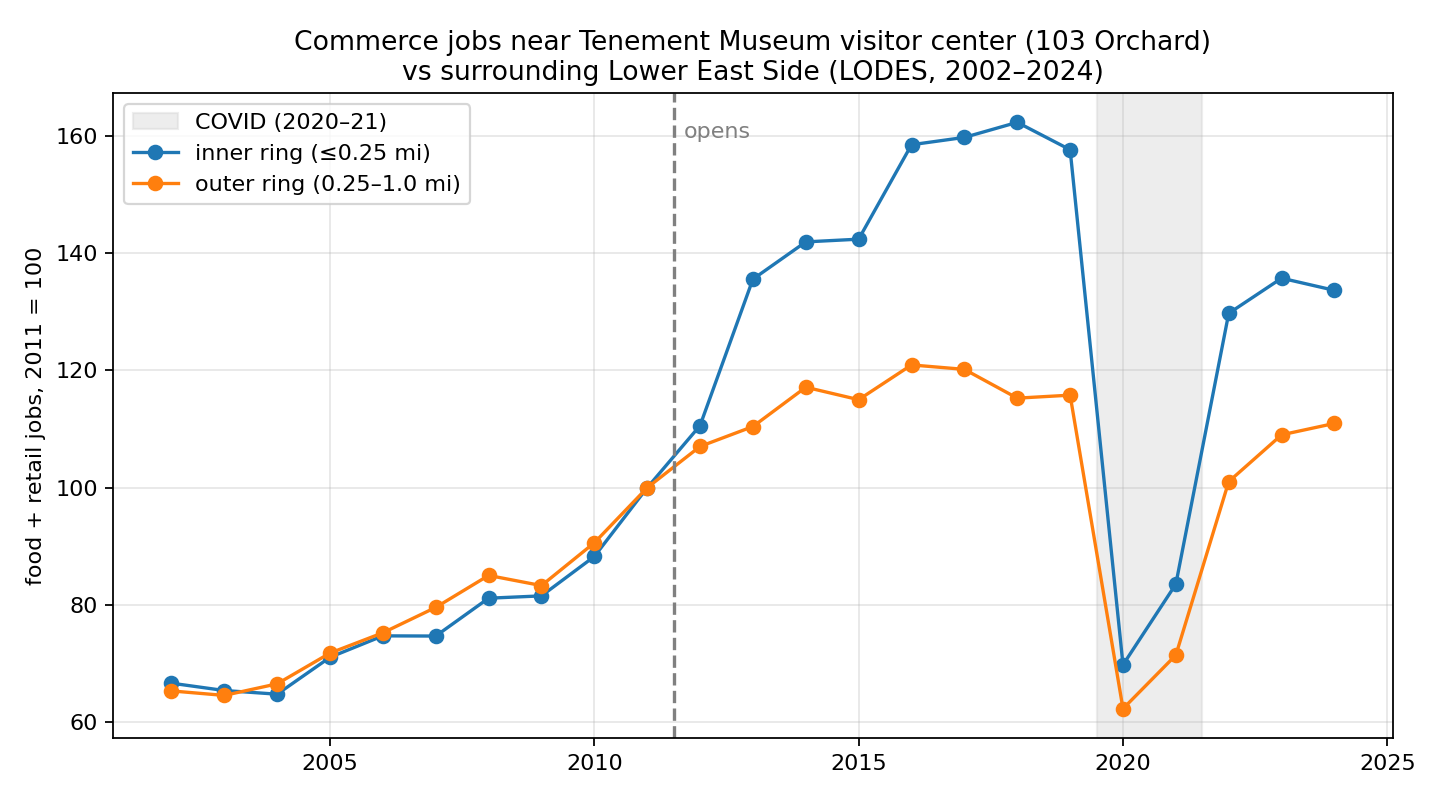

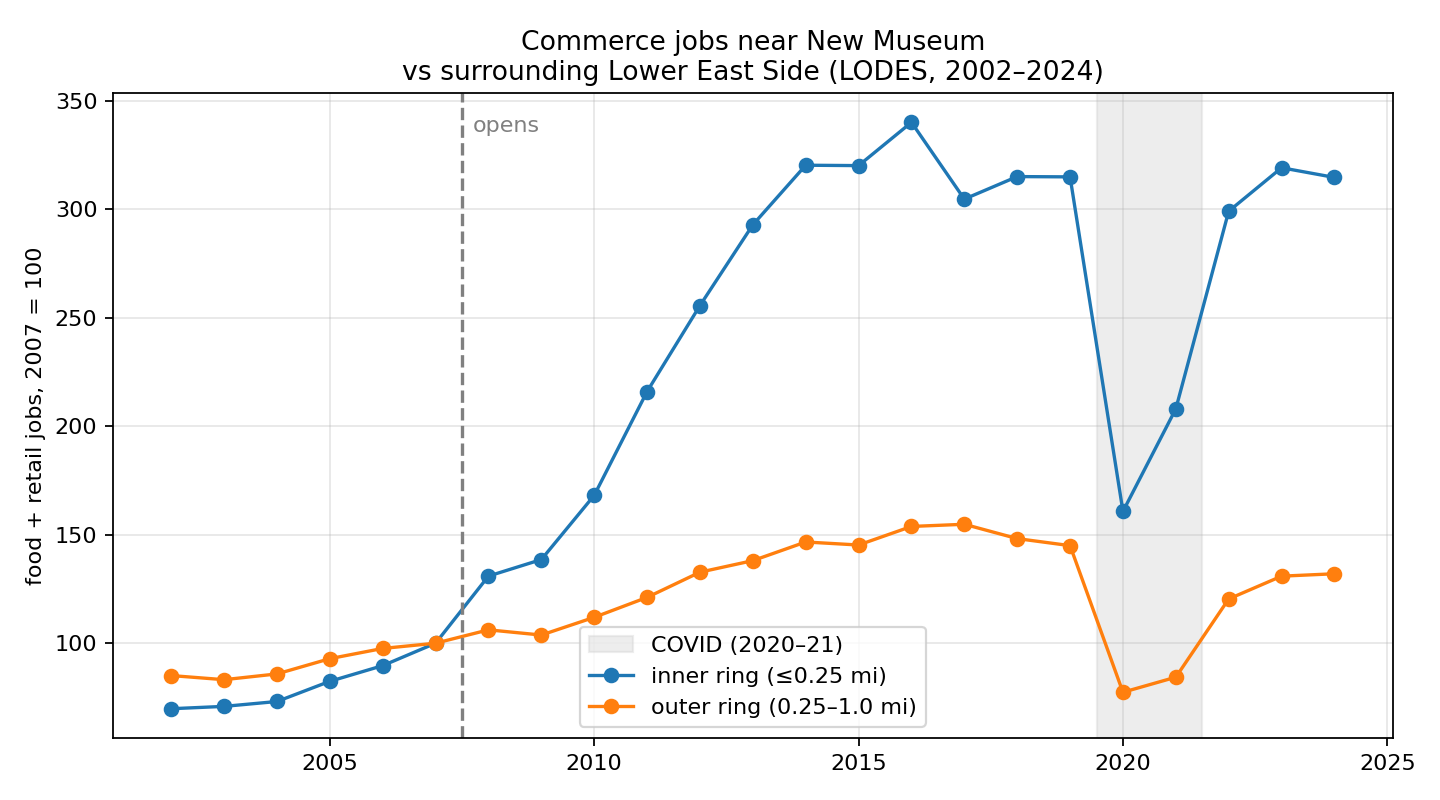

In [3]:
""" 
Evaluating impact of cultural anchor points to building up commerce in the surrounding area

Looking at the Tenement Museum and New Museum's impact to the LES as cultural anchors
Also to note the chart shows when each respective museum opens on the chart itself

"""
display(Image("notebooks/outputs/lodes_tenement_museum_chart.png"))

display(Image("notebooks/outputs/lodes_new_museum_chart.png"))

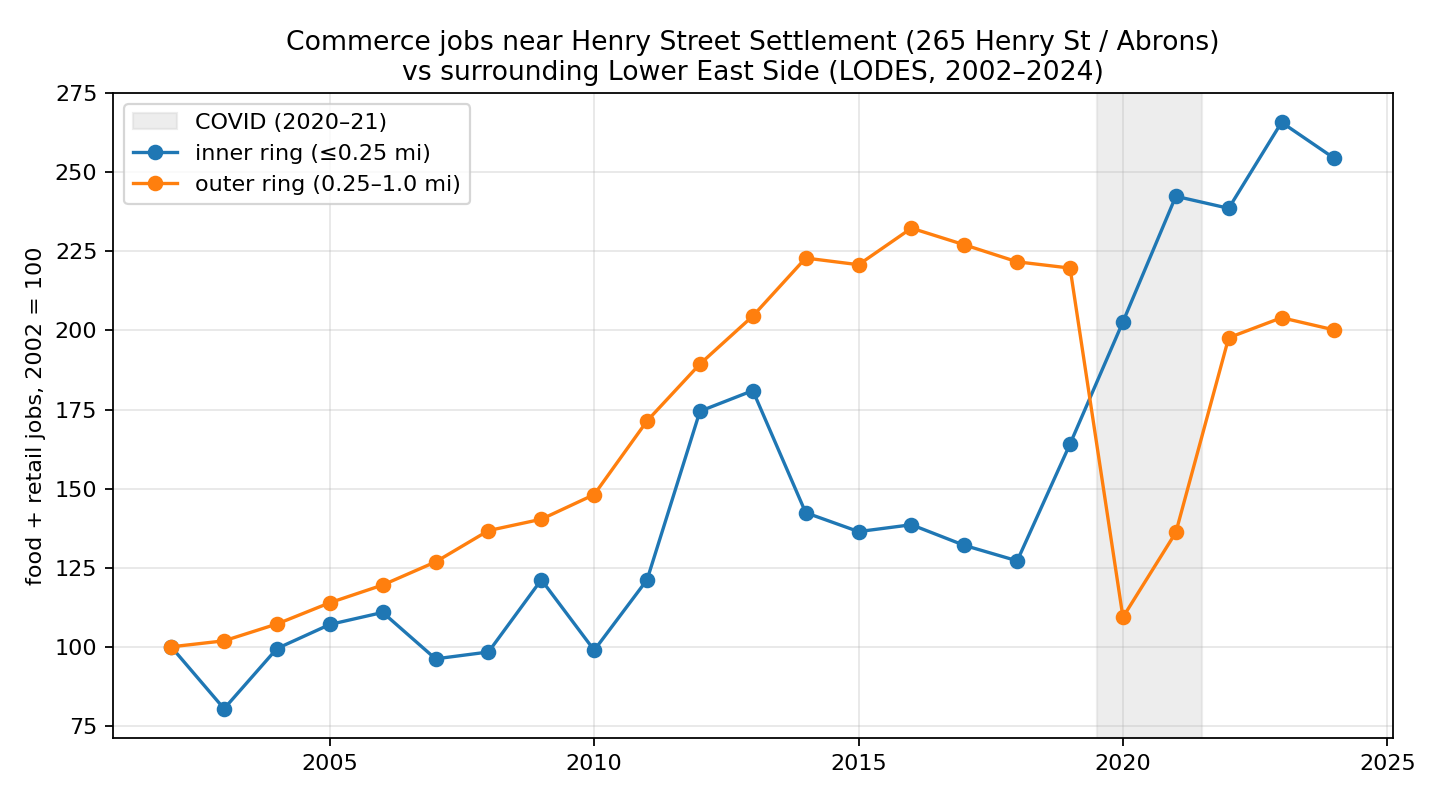

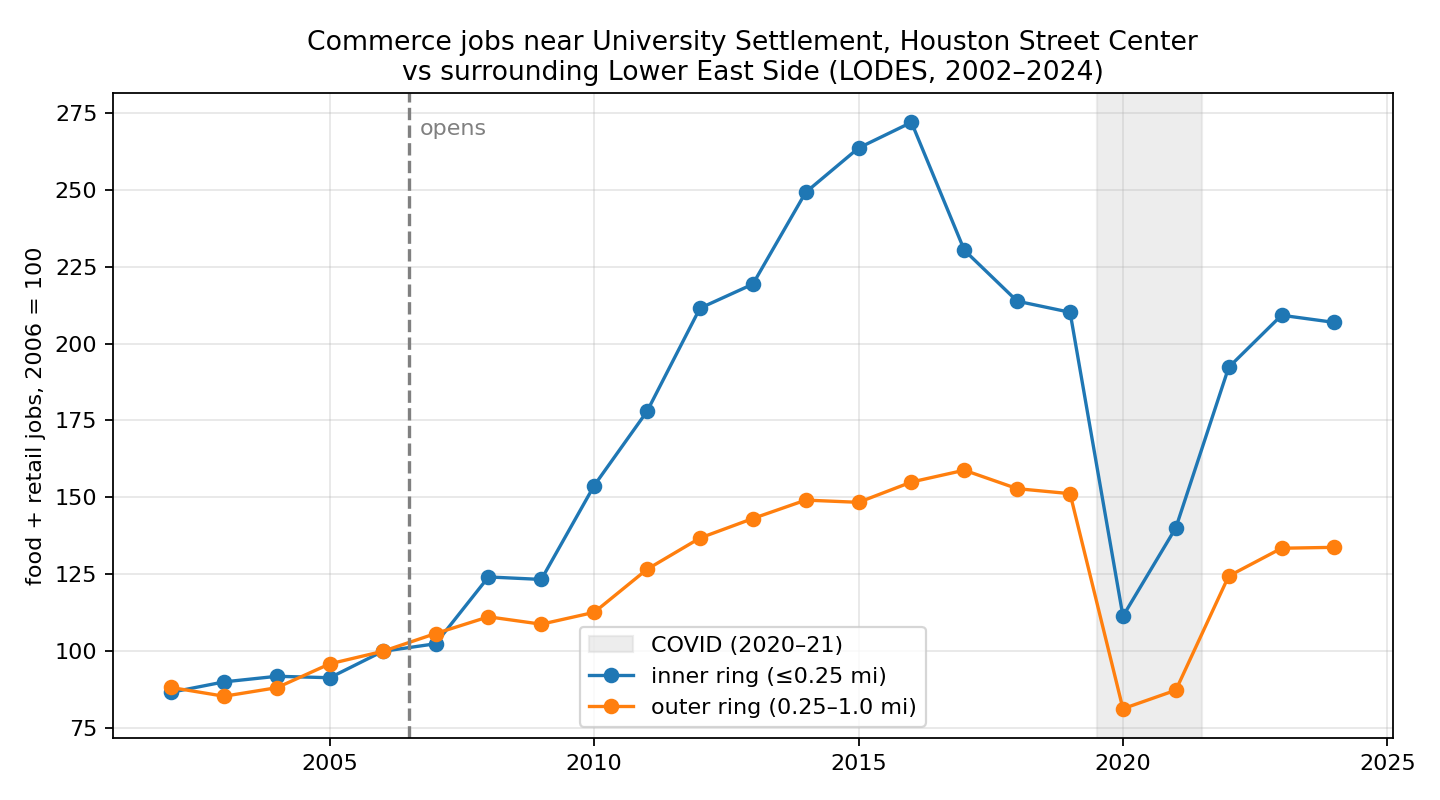

In [4]:
"""
Evaluating impact of nonprofits as anchor points to building up commerce in the surrounding area

Looking at Henry Street Settlement and University Settlement's impact to the LES as nonprofit anchors

Henry Street Settlement doesn't have an open date on here because their open date does predate what we have access to
"""

display(Image("notebooks/outputs/lodes_henry_street_chart.png"))

display(Image("notebooks/outputs/lodes_houston_st_center_chart.png"))

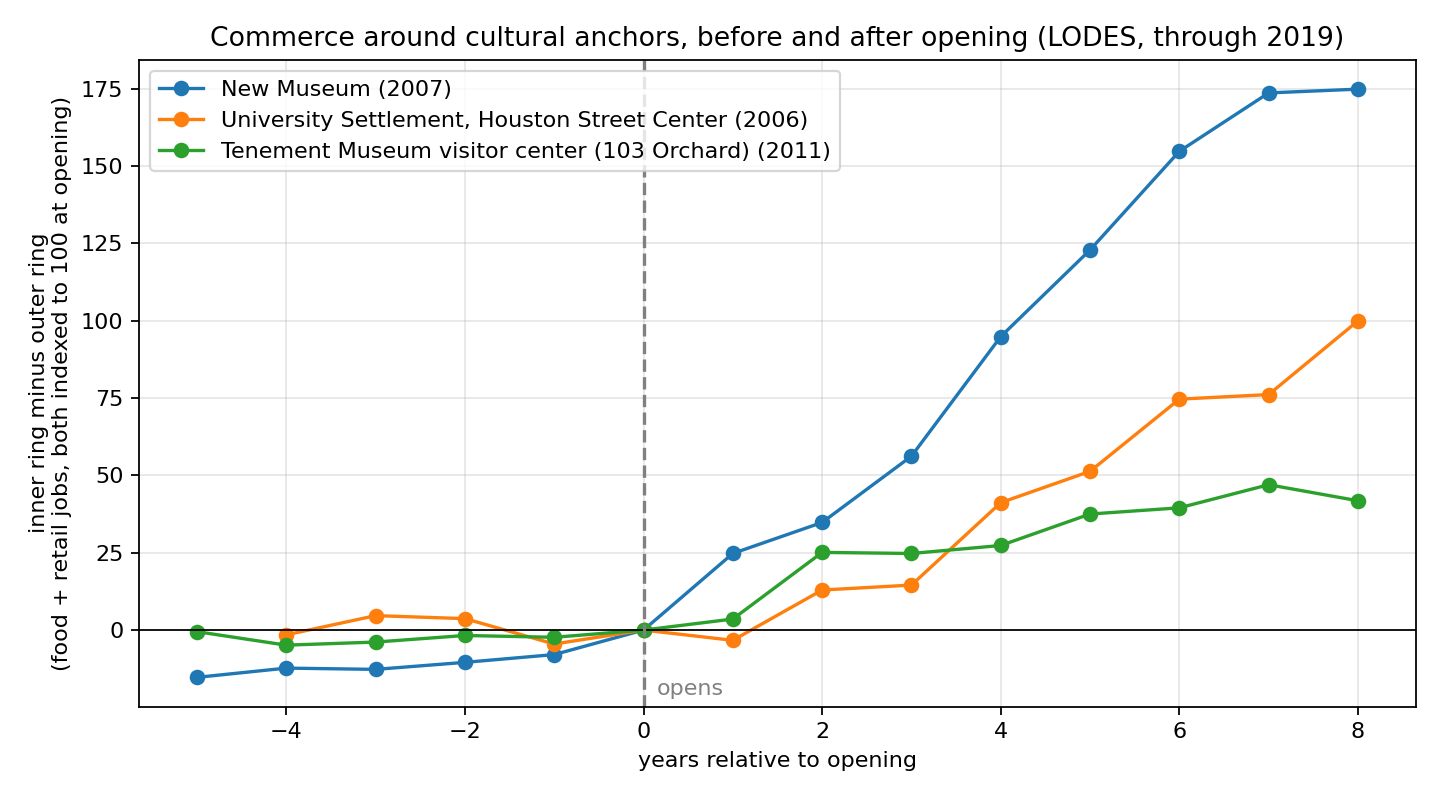

In [5]:
"""
Showing these businesses impacting new jobs overlayed together based on how much time elapsed from the time each building opened

Note: Henry Street is not part of this because its opening predated what we have access to
"""

display(Image("notebooks/outputs/lodes_event_time_overlay.png"))

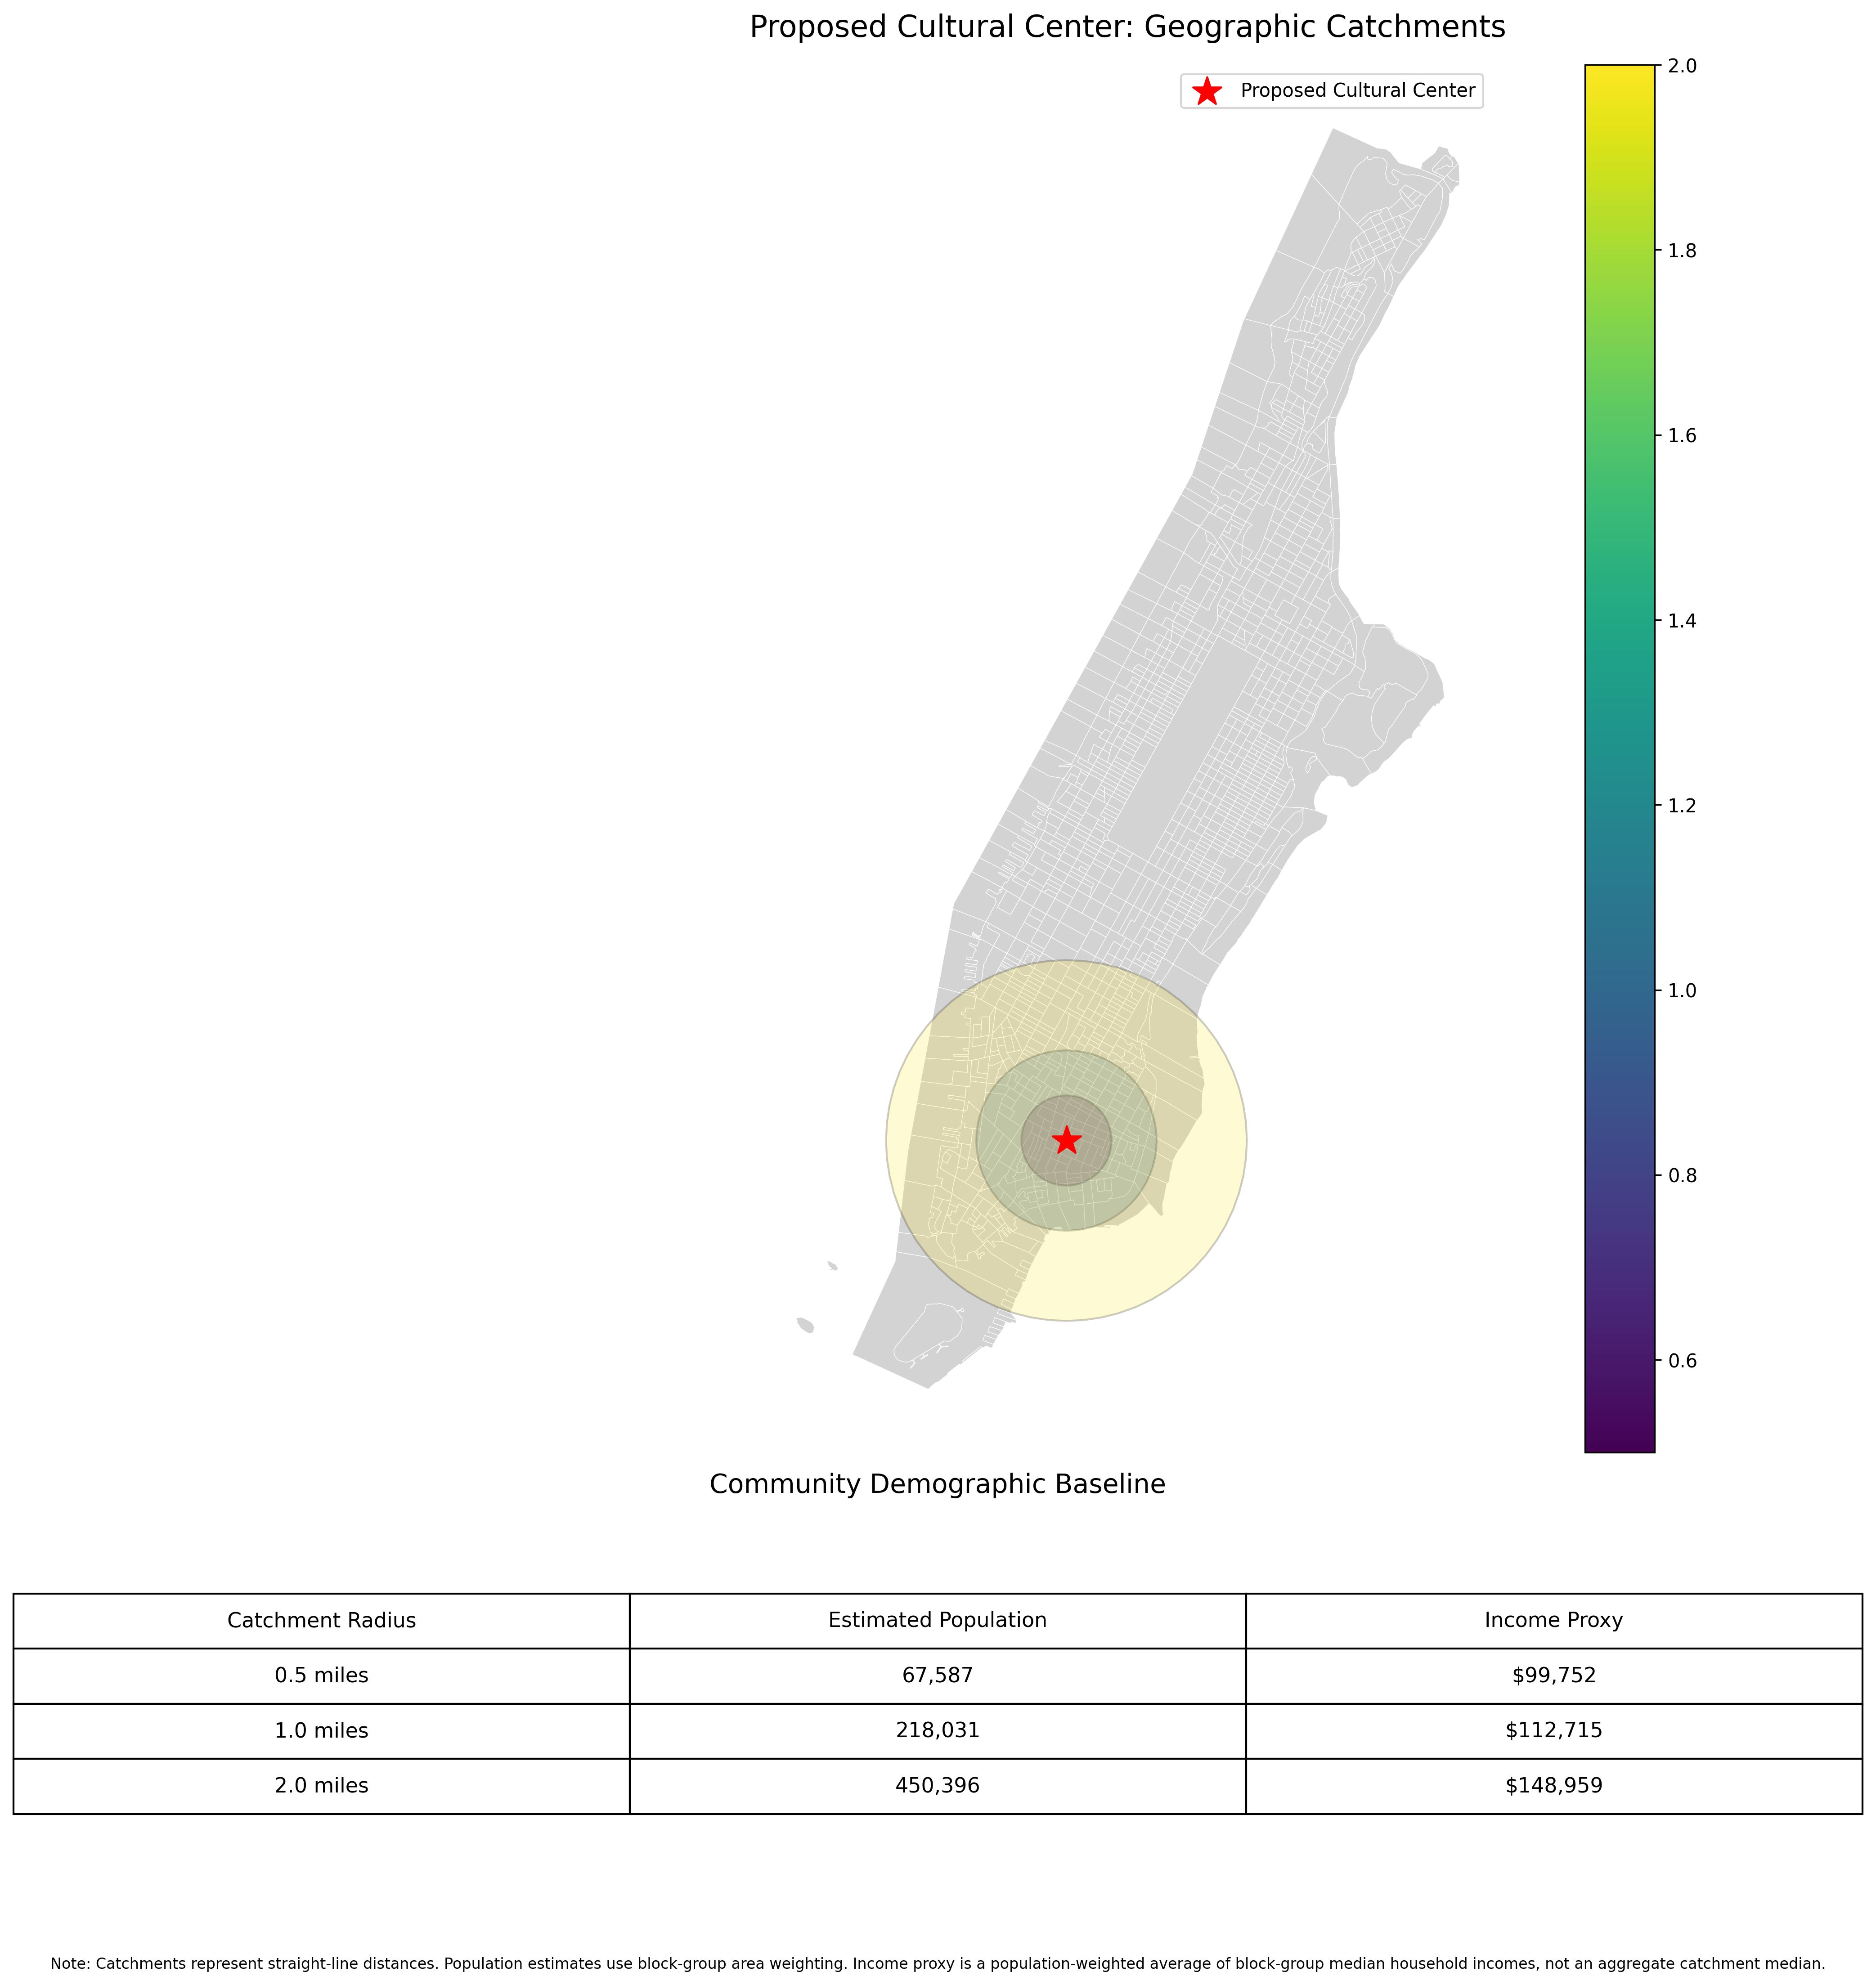

In [41]:
"""
Looking at geographical catchments - relative populations that are in the radius (0.5 vs 1 vs 2 miles)
"""

display(Image("notebooks/outputs/geographic_catchments_demographics.png"))

In [ ]:
"""
Other notes: 

15% is community impact
# 45% is commerce
# 
# 
# Elizabeth Street Garden
# Anchoring - Tenement Museum, Henry st and univ settlement, girls club
# 6-8 food trucks, demolish building

# Cultural gap because Tenement museum only has a few eras or years
# submission early next month
# years 1 and 2 are $0
# green space + nature wall then cafe then building
"""


=== New Museum (opened 2007; 54 inner blocks) ===
                                      inner_jobs_at_open  pre_inner_pct  pre_outer_pct  pre_gap  post_inner_pct  post_outer_pct  post_gap  diff_in_diff
spec                                                                                                                                                   
main                                                2311           43.3           17.5     25.7           140.5            36.6     104.0          78.2
excl Whole Foods / Houston St Center                2193           45.0           17.5     27.5           119.4            36.6      82.8          55.3
inner<=0.5mi                                       18240           23.0           15.9      7.1            52.2            36.6      15.6           8.5


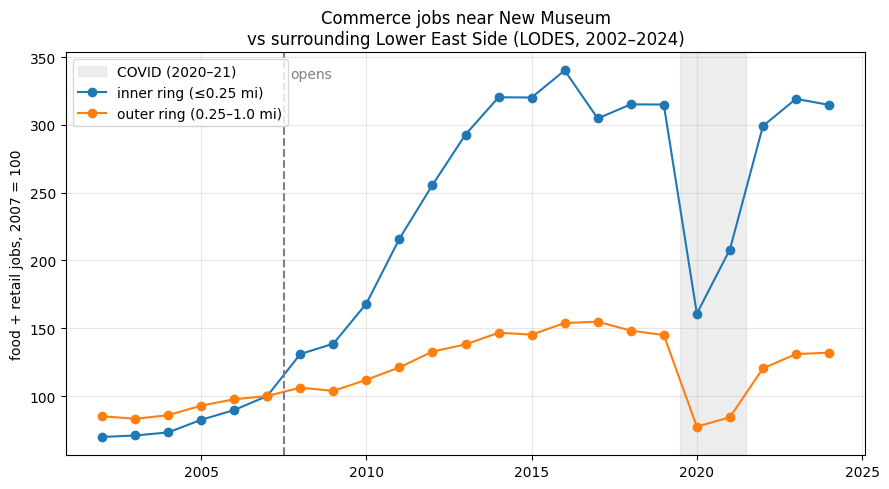


=== University Settlement, Houston Street Center (opened 2006; 47 inner blocks) ===
                       inner_jobs_at_open  pre_inner_pct  pre_outer_pct  pre_gap  post_inner_pct  post_outer_pct  post_gap  diff_in_diff
spec                                                                                                                                    
main                                 3852            5.4            8.7     -3.3           110.2            51.2      58.9          62.2
excl New Museum block                3684            4.0            8.7     -4.7            86.0            51.2      34.8          39.5
inner<=0.5mi                        19237           10.7            7.2      3.4            71.5            46.2      25.3          21.8


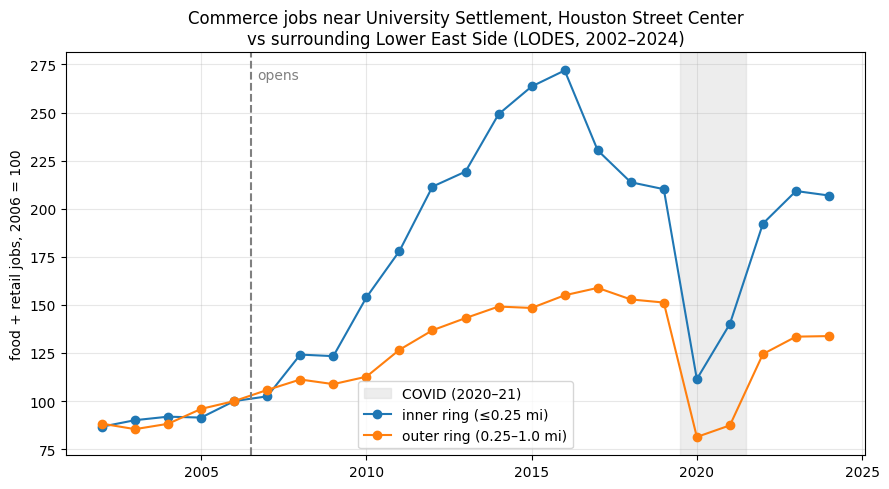


=== Tenement Museum visitor center (103 Orchard) (opened 2011; 51 inner blocks) ===
                     inner_jobs_at_open  pre_inner_pct  pre_outer_pct  pre_gap  post_inner_pct  post_outer_pct  post_gap  diff_in_diff
spec                                                                                                                                  
main                               3039           24.2           26.2     -2.0            57.6            15.8      41.8          43.8
excl Essex Crossing                2275           22.5           26.2     -3.6            34.9            15.8      19.1          22.7
post to 2017                       3039           24.2           26.2     -2.0            59.7            20.2      39.5          41.5
inner<=0.5mi                      13970           37.2           21.8     15.4            34.1            11.7      22.5           7.1


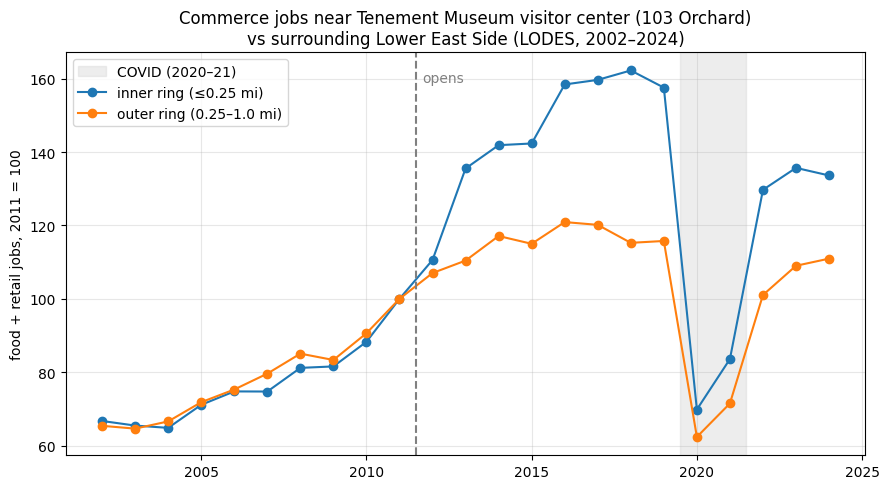


=== Henry Street Settlement (265 Henry St / Abrons) (standing anchor, predates data; 19 inner blocks) ===
                     inner_jobs_at_open pre_inner_pct pre_outer_pct pre_gap  post_inner_pct  post_outer_pct  post_gap diff_in_diff
spec                                                                                                                              
main                                184          None          None    None            64.1           119.7     -55.6         None
excl Essex Crossing                 184          None          None    None            19.6           121.0    -101.4         None
inner<=0.5mi                       2334          None          None    None            66.0           130.9     -64.9         None


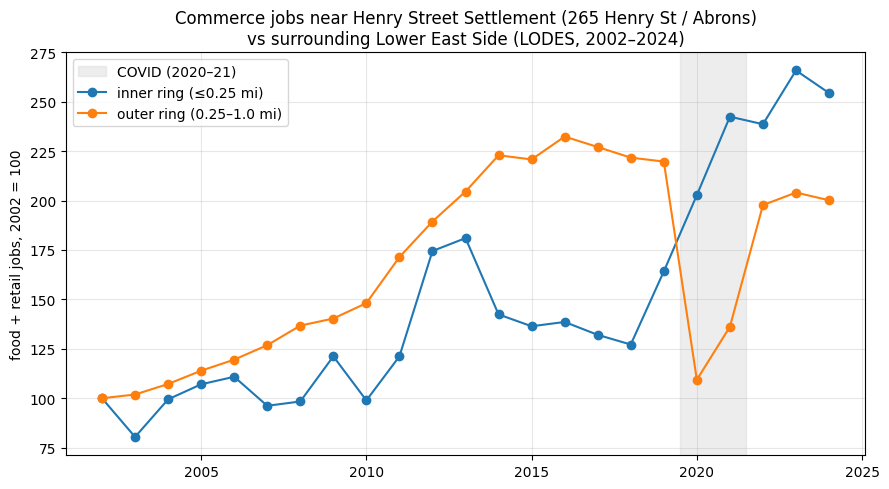


wrote lodes_anchors_summary.csv and per-anchor rings/charts


In [5]:
# ---- cell 5: per-anchor jobs analysis (cell 0 already moved the kernel to the project root, lescc/)
#from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#OUT = Path("notebooks/outputs")        # every chart and table goes here
#OUT.mkdir(parents=True, exist_ok=True)

DATA_DIR = "data/lodes"  # raw LODES downloads live here
YEARS = list(range(2002, 2025))
INNER_MI, OUTER_MI = 0.25, 1.0

ANCHORS = [
    {   # already run in 03, repeated here with the post window cut at 2019
        "name": "New Museum", "slug": "new_museum", "lat": 40.7224, "lon": -73.9929,
        "open_year": 2007, "pre": (2002, 2007), "post": (2008, 2019),
        "exclude": [("Whole Foods / Houston St Center", 40.7245, -73.9925, 0.10)],
    },
    {
        "name": "University Settlement, Houston Street Center", "slug": "houston_st_center",
        "lat": 40.7246, "lon": -73.9926,
        "open_year": 2006, "pre": (2002, 2005), "post": (2006, 2019),
        "exclude": [("New Museum block", 40.7224, -73.9929, 0.08)],
    },
    {   # museum dates to 1988; the event is its new visitor center at 103 Orchard, opened 2011
        "name": "Tenement Museum visitor center (103 Orchard)", "slug": "tenement_museum",
        "lat": 40.7186, "lon": -73.9900,
        "open_year": 2011, "pre": (2005, 2010), "post": (2011, 2019),
        "exclude": [("Essex Crossing", 40.7182, -73.9881, 0.15)],
        "alt_post": (2011, 2017),   # before Essex Crossing retail opened
    },
    {   # standing anchor: main complex (1893) and Abrons Arts Center (1975) predate the data,
        # so there is no before/after. Chart compares ring growth over the whole span instead.
        "name": "Henry Street Settlement (265 Henry St / Abrons)", "slug": "henry_street",
        "lat": 40.7138, "lon": -73.9840,
        "open_year": None, "pre": None, "post": (2002, 2019),
        "exclude": [("Essex Crossing", 40.7182, -73.9881, 0.15)],
    },
]


def haversine_mi(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))


# ---- load once: Manhattan block coordinates and all years of jobs
xw = pd.read_csv(f"{DATA_DIR}/ny_xwalk.csv.gz", usecols=["tabblk2020", "cty", "blklatdd", "blklondd"],
                 dtype={"tabblk2020": str, "cty": str}, compression="gzip")
xw = xw[xw.cty == "36061"].reset_index(drop=True)

frames = []
for y in YEARS:
    w = pd.read_csv(f"{DATA_DIR}/ny_wac_S000_JT00_{y}.csv.gz", usecols=["w_geocode", "CNS07", "CNS18"],
                    dtype={"w_geocode": str}, compression="gzip")
    w = w[w.w_geocode.str.startswith("36061")].copy()
    w["year"] = y
    frames.append(w)
jobs = pd.concat(frames, ignore_index=True)
jobs["commerce"] = jobs.CNS07 + jobs.CNS18
jobs = jobs.merge(xw[["tabblk2020", "blklatdd", "blklondd"]], left_on="w_geocode", right_on="tabblk2020")


def growth(rings, ring, a, b):
    return 100 * (rings.loc[b, ring] / rings.loc[a, ring] - 1)


def did(df, open_year, pre, post, label):
    rings = df.groupby(["year", "ring"]).commerce.sum().unstack("ring")
    post_in, post_out = growth(rings, "inner", *post), growth(rings, "outer", *post)
    if open_year is None:   # standing anchor: no before period, so no diff-in-diff
        return rings, {
            "spec": label, "inner_jobs_at_open": int(rings.loc[post[0], "inner"]),
            "pre_inner_pct": None, "pre_outer_pct": None, "pre_gap": None,
            "post_inner_pct": round(post_in, 1), "post_outer_pct": round(post_out, 1),
            "post_gap": round(post_in - post_out, 1), "diff_in_diff": None,
        }
    pre_in, pre_out = growth(rings, "inner", *pre), growth(rings, "outer", *pre)
    return rings, {
        "spec": label, "inner_jobs_at_open": int(rings.loc[open_year, "inner"]),
        "pre_inner_pct": round(pre_in, 1), "pre_outer_pct": round(pre_out, 1),
        "pre_gap": round(pre_in - pre_out, 1),
        "post_inner_pct": round(post_in, 1), "post_outer_pct": round(post_out, 1),
        "post_gap": round(post_in - post_out, 1),
        "diff_in_diff": round((post_in - post_out) - (pre_in - pre_out), 1),
    }


summary = []
for a in ANCHORS:
    d = jobs.copy()
    d["dist"] = haversine_mi(d.blklatdd, d.blklondd, a["lat"], a["lon"])
    d = d[d.dist <= OUTER_MI].copy()
    d["ring"] = np.where(d.dist <= INNER_MI, "inner", "outer")
    base_year = a["open_year"] if a["open_year"] is not None else a["post"][0]
    n_in = d[d.year == base_year].ring.eq("inner").sum()

    rings, row = did(d, a["open_year"], a["pre"], a["post"], "main")
    main = rings
    rows = [row]
    for label, lat, lon, r in a["exclude"]:
        dd = d[haversine_mi(d.blklatdd, d.blklondd, lat, lon) > r]
        rows.append(did(dd, a["open_year"], a["pre"], a["post"], f"excl {label}")[1])
    if "alt_post" in a:
        rows.append(did(d, a["open_year"], a["pre"], a["alt_post"], f"post to {a['alt_post'][1]}")[1])
    d2 = d.copy(); d2["ring"] = np.where(d2.dist <= 0.5, "inner", "outer")
    rows.append(did(d2, a["open_year"], a["pre"], a["post"], "inner<=0.5mi")[1])
    for r in rows:
        r.update({"anchor": a["name"], "open_year": a["open_year"],
                  "pre": f"{a['pre'][0]}-{a['pre'][1]}" if a["pre"] else None, "post": f"{r['spec'].replace('post to ', '') if r['spec'].startswith('post to') else a['post'][1]}"})
        summary.append(r)

    main = main.assign(inner_idx=100 * main.inner / main.loc[base_year, "inner"],
                       outer_idx=100 * main.outer / main.loc[base_year, "outer"])
    main.to_csv(OUT / f"lodes_{a['slug']}_rings.csv")
    print(f"\n=== {a['name']} ({'opened ' + str(a['open_year']) if a['open_year'] else 'standing anchor, predates data'}; {n_in} inner blocks) ===")
    print(pd.DataFrame(rows).set_index("spec")[["inner_jobs_at_open", "pre_inner_pct", "pre_outer_pct",
                                                 "pre_gap", "post_inner_pct", "post_outer_pct", "post_gap",
                                                 "diff_in_diff"]].to_string())

    fig, ax = plt.subplots(figsize=(9, 5))
    m = main                                   # full span; the DiD numbers above still stop at 2019
    ax.axvspan(2019.5, 2021.5, color="lightgray", alpha=0.4, label="COVID (2020–21)")
    ax.plot(m.index, m.inner_idx, marker="o", label=f"inner ring (≤{INNER_MI} mi)")
    ax.plot(m.index, m.outer_idx, marker="o", label=f"outer ring ({INNER_MI}–{OUTER_MI} mi)")
    if a["open_year"] is not None:
        ax.axvline(a["open_year"] + 0.5, color="gray", linestyle="--")
        ax.text(a["open_year"] + 0.7, ax.get_ylim()[1] * 0.97, "opens", va="top", color="gray")
    ax.set_ylabel(f"food + retail jobs, {base_year} = 100")
    ax.set_title(f"Commerce jobs near {a['name']}\nvs surrounding Lower East Side (LODES, {YEARS[0]}–{YEARS[-1]})")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(OUT / f"lodes_{a['slug']}_chart.png", dpi=160); plt.show(); plt.close(fig)

pd.DataFrame(summary).to_csv(OUT / "lodes_anchors_summary.csv", index=False)
print("\nwrote lodes_anchors_summary.csv and per-anchor rings/charts")

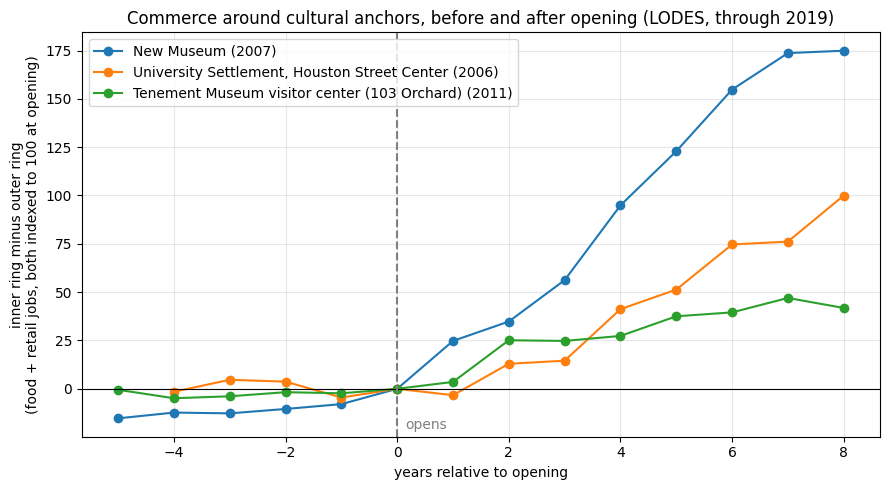

wrote lodes_event_time_overlay.png


In [6]:

# ---------------------------------------------------------------- event-time overlay
# One chart, x = years relative to each anchor's opening, y = inner ring index minus
# outer ring index (both indexed to 100 at opening). Flat near zero before opening means
# the rings were tracking each other; a climb after means the inner ring pulled ahead.
# Standing anchors (no opening year) are skipped. Years after 2019 are dropped so COVID
# doesn't enter the picture.
EVENT_WINDOW = (-5, 8)
fig, ax = plt.subplots(figsize=(9, 5))
for a in ANCHORS:
    if a["open_year"] is None:
        continue
    r = pd.read_csv(OUT / f"lodes_{a['slug']}_rings.csv", index_col="year").loc[:2019]
    gap = (r.inner_idx - r.outer_idx)
    gap.index = gap.index - a["open_year"]
    gap = gap.loc[EVENT_WINDOW[0]:EVENT_WINDOW[1]]
    ax.plot(gap.index, gap.values, marker="o", label=f"{a['name']} ({a['open_year']})")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--")
ax.text(0.15, ax.get_ylim()[0] * 0.9, "opens", va="bottom", color="gray")
ax.set_xlabel("years relative to opening")
ax.set_ylabel("inner ring minus outer ring\n(food + retail jobs, both indexed to 100 at opening)")
ax.set_title("Commerce around cultural anchors, before and after opening (LODES, through 2019)")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "lodes_event_time_overlay.png", dpi=160); plt.show(); plt.close(fig)
print("wrote lodes_event_time_overlay.png")

In [13]:
######### Code for geographic catchment #######
#from pathlib import Path
from io import BytesIO

import geopandas as gpd
#import pandas as pd
import requests
#import matplotlib.pyplot as plt

from shapely.geometry import Point

CENSUS_API_KEY = "432b14106d96a4cfc17bb03ec1aead28cf7a8233"

# Project directory
PROJECT_DIR = Path.cwd().parent

# Data directories
DATA_DIR = PROJECT_DIR / "data" / "community_baseline"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Create directories if they don't already exist
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_DIR}")
print(f"Raw data directory: {RAW_DIR}")
print(f"Processed data directory: {PROCESSED_DIR}")

Project directory: /Users/margosuryanaga/Documents
Raw data directory: /Users/margosuryanaga/Documents/data/community_baseline/raw
Processed data directory: /Users/margosuryanaga/Documents/data/community_baseline/processed


In [9]:
# Proposed cultural center location
SITE_LAT = 40.719525444625965
SITE_LON = -73.99021199127341

# Census geography
ACS_YEAR = 2024
STATE = "36"   # New York
COUNTY = "061" # New York County (Manhattan)

# Initial catchment radii, in miles
CATCHMENT_MILES = [0.5, 1.0, 2.0]

# Coordinate reference system for NYC distance calculations
NYC_CRS = "EPSG:2263"

In [14]:
# Census ACS API endpoint
acs_url = f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5"

# ACS variables
variables = [
    "NAME",
    "B01003_001E",
    "B19013_001E",
    "B17001_001E",
    "B17001_002E",
    "B17001_026E",
]

params = {
    "get": ",".join(variables),
    "for": "block group:*",
    "in": f"state:{STATE} county:{COUNTY} tract:*",
    "key": CENSUS_API_KEY,
}

response = requests.get(acs_url, params=params, timeout=60)
response.raise_for_status()

records = response.json()

acs = pd.DataFrame(
    records[1:],
    columns=records[0]
)

# Construct census block group GEOID
acs["GEOID"] = (
    acs["state"]
    + acs["county"]
    + acs["tract"]
    + acs["block group"]
)

# Convert estimates to numeric values
numeric_columns = [
    "B01003_001E",
    "B19013_001E",
    "B17001_001E",
    "B17001_002E",
    "B17001_026E",
]

for col in numeric_columns:
    acs[col] = pd.to_numeric(acs[col], errors="coerce")

# Combine male and female below-poverty estimates
acs["poverty_below"] = (
    acs["B17001_002E"] + acs["B17001_026E"]
)

# Save raw ACS data
acs.to_csv(
    RAW_DIR / "acs_manhattan_block_groups.csv",
    index=False
)

print(f"Retrieved {len(acs)} census block groups.")
display(acs.head())

Retrieved 1292 census block groups.


,NAME,B01003_001E,B19013_001E,B17001_001E,B17001_002E,B17001_026E,state,county,tract,block group,GEOID,poverty_below
0,Block Group 1; Census Tract 1; New York County...,0,-666666666,NaN,NaN,NaN,36,061,000100,1,360610001001,NaN
1,Block Group 0; Census Tract 2.01; New York Cou...,0,-666666666,NaN,NaN,NaN,36,061,000201,0,360610002010,NaN
2,Block Group 1; Census Tract 2.01; New York Cou...,582,68603,NaN,NaN,NaN,36,061,000201,1,360610002011,NaN
3,Block Group 2; Census Tract 2.01; New York Cou...,2084,28359,NaN,NaN,NaN,36,061,000201,2,360610002012,NaN
4,Block Group 0; Census Tract 2.02; New York Cou...,0,-666666666,NaN,NaN,NaN,36,061,000202,0,360610002020,NaN


In [18]:
# TIGER/Line geographic boundary download
tiger_url = (
    f"https://www2.census.gov/geo/tiger/TIGER{ACS_YEAR}/BG/"
    f"tl_{ACS_YEAR}_{STATE}_bg.zip"
)

response = requests.get(tiger_url, timeout=120)
response.raise_for_status()

# Read shapefile directly from downloaded ZIP
geography = gpd.read_file(BytesIO(response.content))

# Filter to Manhattan County
geography = geography[
    geography["COUNTYFP"] == COUNTY
].copy()

#print("Available columns:")
#print(geography.columns.tolist())

# Keep relevant geographic fields
geography = geography[
    ["GEOID", "NAMELSAD", "geometry"]
].copy()

print(f"Retrieved {len(geography)} Manhattan block groups.")

display(geography.head())

Retrieved 1292 Manhattan block groups.


,GEOID,NAMELSAD,geometry
963,360610080005,Block Group 5,"POLYGON ((-73.97816 40.75146, -73.97768 40.752..."
964,360610002025,Block Group 5,"POLYGON ((-73.98225 40.70583, -73.98091 40.705..."
965,360610012003,Block Group 3,"POLYGON ((-73.98117 40.71538, -73.98088 40.715..."
1461,360610024002,Block Group 2,"POLYGON ((-73.97471 40.72188, -73.97465 40.722..."
1462,360610223020,Block Group 0,"POLYGON ((-73.9659 40.82346, -73.96572 40.8237..."


In [19]:
# Merge ACS demographic data with geographic boundaries
block_groups = geography.merge(
    acs,
    on="GEOID",
    how="inner"
)

print(f"Geographic records: {len(geography)}")
print(f"ACS records: {len(acs)}")
print(f"Matched records: {len(block_groups)}")

display(
    block_groups[
        [
            "GEOID",
            "NAMELSAD",
            "B01003_001E",
            "B19013_001E",
            "B17001_001E",
            "poverty_below"
        ]
    ].head()
)

Geographic records: 1292
ACS records: 1292
Matched records: 1292


,GEOID,NAMELSAD,B01003_001E,B19013_001E,B17001_001E,poverty_below
0,360610080005,Block Group 5,0,-666666666,NaN,NaN
1,360610002025,Block Group 5,0,-666666666,NaN,NaN
2,360610012003,Block Group 3,1698,159375,NaN,NaN
3,360610024002,Block Group 2,0,-666666666,NaN,NaN
4,360610223020,Block Group 0,0,-666666666,NaN,NaN


In [20]:
# Convert block groups to NYC State Plane coordinates
block_groups = block_groups.to_crs(epsg=2263)

# Define proposed cultural center location
site = gpd.GeoSeries(
    [Point(SITE_LON, SITE_LAT)],
    crs="EPSG:4326"
).to_crs(epsg=2263).iloc[0]

# Calculate block group land area in square feet
block_groups["block_group_area"] = (
    block_groups.geometry.area
)

print("Coordinate reference system:", block_groups.crs)
print("Proposed site coordinates:", site)

Coordinate reference system: EPSG:2263
Proposed site coordinates: POINT (986963.2322799859 201419.1997233332)


In [21]:
# Create catchment buffers
catchments = {}

for radius in CATCHMENT_MILES:
    catchments[radius] = site.buffer(radius * 5280)

# Create a GeoDataFrame for visualization
catchment_gdf = gpd.GeoDataFrame(
    {
        "radius_miles": list(catchments.keys()),
        "geometry": list(catchments.values())
    },
    crs="EPSG:2263"
)

display(catchment_gdf)

,radius_miles,geometry
0,0.5,"POLYGON ((989603.232 201419.2, 989590.52 20116..."
1,1.0,"POLYGON ((992243.232 201419.2, 992217.808 2009..."
2,2.0,"POLYGON ((997523.232 201419.2, 997472.383 2003..."


In [38]:
# Store catchment-level results
catchment_results = []

for radius, buffer in catchments.items():

    # Calculate intersection between each block group and catchment
    intersections = block_groups.geometry.intersection(buffer)

    # Calculate proportion of each block group within catchment
    block_groups["area_share"] = (
        intersections.area / block_groups["block_group_area"]
    ).clip(0, 1)

    # Estimate population within catchment
    block_groups["weighted_population"] = (
        block_groups["B01003_001E"]
        * block_groups["area_share"]
    )

    # Estimate poverty universe within catchment
    block_groups["weighted_poverty_universe"] = (
        block_groups["B17001_001E"]
        * block_groups["area_share"]
    )

    # Estimate population below poverty level
    block_groups["weighted_poverty_count"] = (
        block_groups["poverty_below"]
        * block_groups["area_share"]
    )

    # Valid population estimates
    valid_population = block_groups[
        block_groups["B01003_001E"].notna()
        & (block_groups["B01003_001E"] >= 0)
    ]

    # Valid poverty estimates
    valid_poverty = block_groups[
        block_groups["B17001_001E"].notna()
        & (block_groups["B17001_001E"] > 0)
        & block_groups["poverty_below"].notna()
        & (block_groups["poverty_below"] >= 0)
        & (block_groups["poverty_below"] <= block_groups["B17001_001E"])
    ]

    # Calculate population
    estimated_population = valid_population[
        "weighted_population"
    ].sum()

    # Calculate poverty rate
    poverty_universe = valid_poverty[
        "weighted_poverty_universe"
    ].sum()

    poverty_count = valid_poverty[
        "weighted_poverty_count"
    ].sum()

    poverty_rate = (
        poverty_count / poverty_universe
        if poverty_universe > 0
        else None
    )

    # Calculate population-weighted average of block-group median incomes
    valid_income = block_groups[
        block_groups["B19013_001E"].notna()
        & (block_groups["B19013_001E"] > 0)
        & block_groups["B01003_001E"].notna()
        & (block_groups["B01003_001E"] > 0)
    ]

    income_weights = (
        valid_income["B01003_001E"]
        * valid_income["area_share"]
    )

    weighted_income_proxy = (
        (
            valid_income["B19013_001E"] * income_weights
        ).sum() / income_weights.sum()
        if income_weights.sum() > 0
        else None
    )

    # Store results
    catchment_results.append({
        "catchment_miles": radius,
        "estimated_population": estimated_population,
        "poverty_universe": poverty_universe,
        "estimated_population_below_poverty": poverty_count,
        "estimated_poverty_rate": poverty_rate,
        "population_weighted_average_block_group_median_income": weighted_income_proxy
    })

# Create summary DataFrame
summary = pd.DataFrame(catchment_results)

display(summary)

,catchment_miles,estimated_population,poverty_universe,estimated_population_below_poverty,estimated_poverty_rate,population_weighted_average_block_group_median_income
0,0.5,67586.560045,0.0,0.0,None,99752.238960
1,1.0,218031.396035,0.0,0.0,None,112714.718159
2,2.0,450395.515553,0.0,0.0,None,148958.757559


In [39]:
# Format results for display
summary_display = summary.copy()

summary_display["estimated_population"] = (
    summary_display["estimated_population"].round(0)
)

summary_display["estimated_poverty_rate"] = (
    summary_display["estimated_poverty_rate"] * 100
).round(1)

summary_display[
    "population_weighted_average_block_group_median_income"
] = summary_display[
    "population_weighted_average_block_group_median_income"
].apply(
    lambda x: f"${x:,.0f}" if pd.notna(x) else "N/A"
)

display(summary_display)

,catchment_miles,estimated_population,poverty_universe,estimated_population_below_poverty,estimated_poverty_rate,population_weighted_average_block_group_median_income
0,0.5,67587.0,0.0,0.0,NaN,"$99,752"
1,1.0,218031.0,0.0,0.0,NaN,"$112,715"
2,2.0,450396.0,0.0,0.0,NaN,"$148,959"


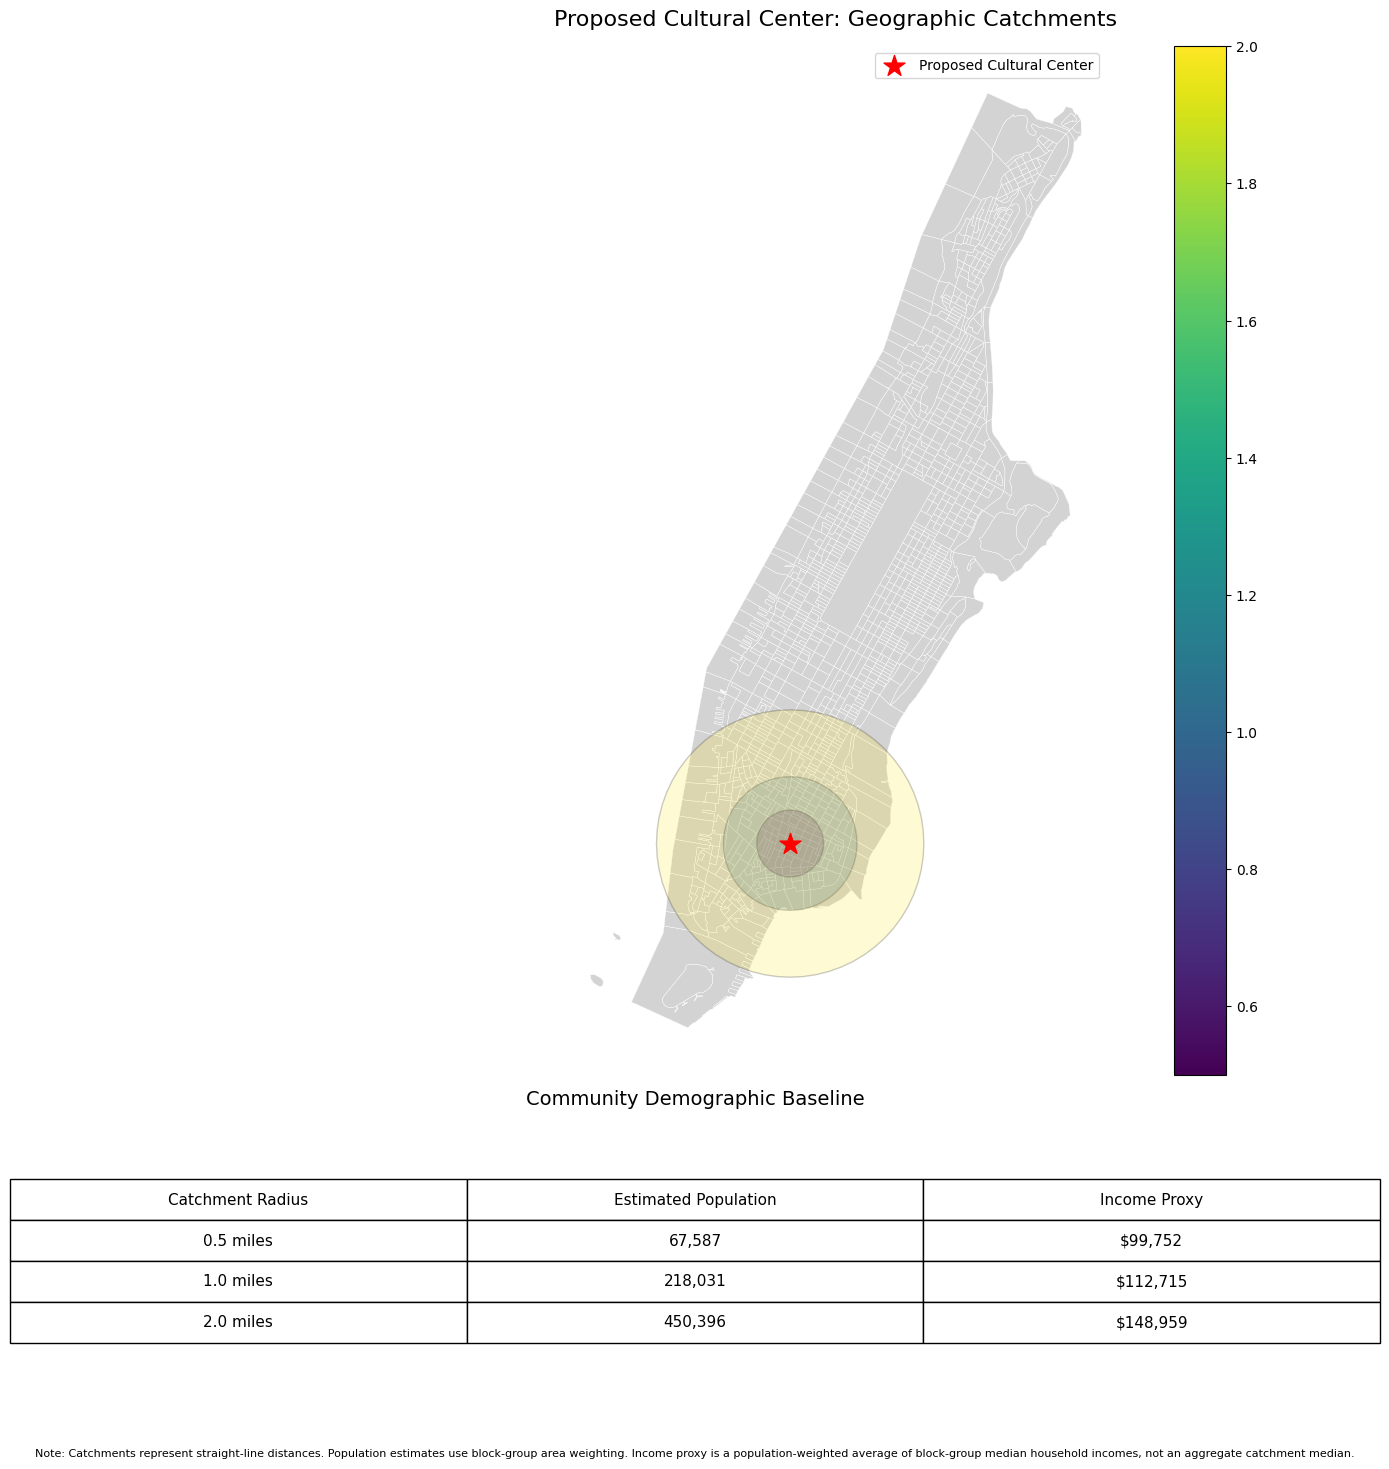

Saved visualization to: notebooks/outputs/geographic_catchments_demographics.png


In [40]:
#import matplotlib.pyplot as plt
#import pandas as pd

# Create figure with map and summary table
fig, (ax_map, ax_table) = plt.subplots(
    2,
    1,
    figsize=(14, 15),
    gridspec_kw={"height_ratios": [4, 1]}
)

# --------------------------------
# 1. Geographic catchment map
# --------------------------------

block_groups.plot(
    ax=ax_map,
    color="lightgray",
    edgecolor="white",
    linewidth=0.3
)

catchment_gdf.plot(
    ax=ax_map,
    column="radius_miles",
    alpha=0.2,
    edgecolor="black",
    legend=True
)

ax_map.scatter(
    site.x,
    site.y,
    color="red",
    marker="*",
    s=250,
    label="Proposed Cultural Center",
    zorder=5
)

ax_map.set_title(
    "Proposed Cultural Center: Geographic Catchments",
    fontsize=16,
    pad=15
)

ax_map.set_axis_off()
ax_map.legend(loc="upper right")

# --------------------------------
# 2. Demographic summary table
# --------------------------------

table_data = summary[
    [
        "catchment_miles",
        "estimated_population",
        "population_weighted_average_block_group_median_income"
    ]
].copy()

# Format values
table_data["catchment_miles"] = (
    table_data["catchment_miles"].map(lambda x: f"{x:.1f} miles")
)

table_data["estimated_population"] = (
    table_data["estimated_population"].map(lambda x: f"{x:,.0f}")
)

table_data[
    "population_weighted_average_block_group_median_income"
] = table_data[
    "population_weighted_average_block_group_median_income"
].map(
    lambda x: f"${x:,.0f}" if pd.notna(x) else "N/A"
)

table_data.columns = [
    "Catchment Radius",
    "Estimated Population",
    "Income Proxy"
]

ax_table.axis("off")

table = ax_table.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

ax_table.set_title(
    "Community Demographic Baseline",
    fontsize=14,
    pad=20
)

# --------------------------------
# 3. Methodology note
# --------------------------------

fig.text(
    0.5,
    0.025,
    "Note: Catchments represent straight-line distances. "
    "Population estimates use block-group area weighting. "
    "Income proxy is a population-weighted average of block-group "
    "median household incomes, not an aggregate catchment median.",
    ha="center",
    fontsize=8,
    wrap=True
)

# --------------------------------
# 4. Save PNG
# --------------------------------

plt.tight_layout(rect=[0, 0.06, 1, 1])

output_path = OUT / "geographic_catchments_demographics.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved visualization to: {output_path}")